# Restaurant Food Wastage Prediction and Management System

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sandeepaddanki1-spec/DM-Project/blob/main/Food_Waste_Analysis_and_Prediction.ipynb)
[![GitHub Repository](https://img.shields.io/badge/GitHub-Repository-blue?logo=github)](https://github.com/sandeepaddanki1-spec/DM-Project)

**Team Members:**
- **G. Bhavyasree** (24501A0558)
- **P. Dimple Hasini** (24501A0549)
- **A. Kalpana** (24501A0509)
- **A. Sandeep** (24501A0502)

**Academic Year:** 2026–2027

---

### Project Overview
**Goal:** Predict restaurant food waste in kilograms ($), classify waste severity into Low / Medium / High tiers, discover structural operational patterns via unsupervised clustering, and generate data-driven actionable kitchen management recommendations.

**Algorithms Used:**
- **Regression:** Linear Regression, Random Forest Regressor, **Gradient Boosting Regressor (Champion: R² = 0.903, RMSE = 8.34 kg)**, XGBoost Regressor
- **Classification:** **Logistic Regression (Selected: 74.4% Accuracy, 0.745 Macro F1)**, Random Forest Classifier, Extra Trees, XGBoost
- **Clustering:** K-Means (=2$, Silhouette = 0.352), Agglomerative Hierarchical Clustering

*This notebook runs seamlessly in Google Colab, Kaggle, and local Jupyter environments.*


## 1. Imports and configuration

In [3]:
import os, sys, glob, json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
TARGET = "food_waste_kg"
DATA_DIR = "/kaggle/input"

print("Ready. Random state:", RANDOM_STATE)

Ready. Random state: 42


## 2. Find and load the dataset files

In [4]:
def find_file(stem, required=True):
    patterns = [
        f"{DATA_DIR}/**/{stem}.csv",
        f"{DATA_DIR}/**/{stem}*.csv",
        f"./dataset/**/{stem}.csv",
        f"./dataset/{stem}.csv",
        f"./data/**/{stem}.csv",
        f"./data/{stem}.csv",
        f"./{stem}.csv",
        f"./{stem}*.csv",
    ]
    hits = []
    for pattern in patterns:
        hits.extend(glob.glob(pattern, recursive=True))
    hits = sorted(set(hits))
    if hits:
        return hits[0]
    if required:
        raise FileNotFoundError(f"Could not find {stem}.csv. Check that the Kaggle dataset is attached.")
    return None

train_path = find_file("train")
test_path = find_file("test")
submission_path = find_file("submission")
extra_path = find_file("food_wastage_data", required=False)

print("train:", train_path)
print("test:", test_path)
print("submission:", submission_path)
print("optional food_wastage_data:", extra_path)

train_raw = pd.read_csv(train_path)
test_raw = pd.read_csv(test_path)
sub_raw = pd.read_csv(submission_path)
extra_raw = pd.read_csv(extra_path, encoding="utf-8-sig") if extra_path else None

print("Shapes -> train:", train_raw.shape, "test:", test_raw.shape, "submission:", sub_raw.shape)
if extra_raw is not None:
    print("Optional extra dataset:", extra_raw.shape)

train: /kaggle/input/datasets/arumallakalpana/messy-food-waste-prediction/train.csv
test: /kaggle/input/datasets/arumallakalpana/messy-food-waste-prediction/test.csv
submission: /kaggle/input/datasets/arumallakalpana/messy-food-waste-prediction/submission.csv
optional food_wastage_data: /kaggle/input/datasets/trevinhannibal/food-wastage-data-in-restaurant/food_wastage_data.csv
Shapes -> train: (911, 12) test: (911, 11) submission: (911, 2)
Optional extra dataset: (1782, 11)


## 3. Dataset inspection

In [5]:
print("TRAIN columns and dtypes:")
print(train_raw.dtypes.to_string())

print("\nMissing values in train:")
print(train_raw.isna().sum()[lambda s: s > 0].to_string() or "No missing values")

print("\nMissing values in test:")
print(test_raw.isna().sum()[lambda s: s > 0].to_string() or "No missing values")

print("\nExact duplicate rows:", int(train_raw.duplicated().sum()))
print("Duplicate rows ignoring ID:", int(train_raw.drop(columns=["ID"], errors="ignore").duplicated().sum()))

for c in ["waste_category", "staff_experience"]:
    if c in train_raw.columns:
        print(f"\nRaw unique values of {c}:", train_raw[c].dropna().unique().tolist())

print("\nNumeric statistics:")
display(train_raw.describe().T.round(2))

skew_value = float(stats.skew(pd.to_numeric(train_raw[TARGET], errors="coerce").dropna()))
print("Target skew:", round(skew_value, 2),
      "| min/median/max:",
      round(float(train_raw[TARGET].min()), 1),
      round(float(train_raw[TARGET].median()), 1),
      round(float(train_raw[TARGET].max()), 1))

print("\nTest columns match train features:", list(test_raw.columns) == [c for c in train_raw.columns if c != TARGET])
print("Submission columns:", list(sub_raw.columns))

if extra_raw is not None:
    print("\nOptional food_wastage_data columns:", extra_raw.columns.tolist())
    print("Shared columns with train:", sorted(set(extra_raw.columns) & set(train_raw.columns)))

TRAIN columns and dtypes:
ID                    int64
date                 object
meals_served          int64
kitchen_staff         int64
temperature_C       float64
humidity_percent    float64
day_of_week           int64
special_event         int64
past_waste_kg       float64
staff_experience     object
waste_category       object
food_waste_kg       float64

Missing values in train:
staff_experience    164

Missing values in test:
staff_experience    164

Exact duplicate rows: 0
Duplicate rows ignoring ID: 0

Raw unique values of waste_category: ['dairy', 'MeAt', 'MEAT', 'Vegetables', 'GRAINS']

Raw unique values of staff_experience: ['intermediate', 'Beginner', 'Intermediate', 'EXPERT']

Numeric statistics:


,count,mean,std,min,25%,50%,75%,max
ID,911.0,528.33,305.07,0.00,266.00,531.00,795.50,1049.00
meals_served,911.0,375.41,502.81,100.00,211.00,306.00,407.00,4730.00
kitchen_staff,911.0,11.90,4.29,5.00,8.00,12.00,15.00,19.00
temperature_C,911.0,22.19,8.92,-10.37,15.68,22.12,28.80,60.00
humidity_percent,911.0,60.76,17.33,30.12,46.02,61.63,75.79,89.98
day_of_week,911.0,3.01,2.01,0.00,1.00,3.00,5.00,6.00
special_event,911.0,0.09,0.28,0.00,0.00,0.00,0.00,1.00
past_waste_kg,911.0,27.02,12.77,5.01,16.09,26.85,38.15,49.80
food_waste_kg,911.0,44.84,27.93,10.82,32.89,41.15,50.05,274.33


Target skew: 4.98 | min/median/max: 10.8 41.1 274.3

Test columns match train features: True
Submission columns: ['ID', 'food_waste_kg']

Optional food_wastage_data columns: ['Type of Food', 'Number of Guests', 'Event Type', 'Quantity of Food', 'Storage Conditions', 'Purchase History', 'Seasonality', 'Preparation Method', 'Geographical Location', 'Pricing', 'Wastage Food Amount']
Shared columns with train: []


## 4. Cleaning and feature-engineering functions

In [6]:
%%writefile food_waste_features.py
import numpy as np
import pandas as pd

EXP_MAP = {"beginner": 0, "intermediate": 1, "expert": 2}
CAT_COLS = ["waste_category", "staff_experience"]
NUM_COLS = [
    "meals_served", "kitchen_staff", "temperature_C", "humidity_percent", "day_of_week",
    "special_event", "past_waste_kg", "year", "month", "day", "day_of_year", "is_weekend",
    "month_sin", "month_cos", "experience_ord", "log_meals", "meals_per_staff",
    "past_waste_per_meal", "past_waste_per_staff", "temp_x_humidity", "hot_day", "meals_x_event"
]

def _clean_text(s):
    s = s.astype(object).map(lambda v: np.nan if pd.isna(v) else str(v).strip().lower())
    return s.replace({"nan": np.nan, "": np.nan, "none": np.nan, "null": np.nan, "na": np.nan})

def clean_raw(df):
    df = df.copy()
    for c in CAT_COLS:
        if c in df:
            df[c] = _clean_text(df[c])
        else:
            df[c] = np.nan

    df["date"] = pd.to_datetime(df["date"], errors="coerce") if "date" in df else pd.NaT

    numeric_cols = ["meals_served", "kitchen_staff", "temperature_C", "humidity_percent",
                    "day_of_week", "special_event", "past_waste_kg"]
    for c in numeric_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce") if c in df else np.nan

    df.loc[df["meals_served"] <= 0, "meals_served"] = np.nan
    df.loc[df["kitchen_staff"] <= 0, "kitchen_staff"] = np.nan
    df.loc[~df["humidity_percent"].between(0, 100), "humidity_percent"] = np.nan
    df.loc[df["past_waste_kg"] < 0, "past_waste_kg"] = np.nan
    df.loc[~df["day_of_week"].between(0, 6), "day_of_week"] = np.nan
    return df

def _div(a, b):
    return a / b.where(b > 0, np.nan)

def add_features(df):
    d = pd.DataFrame(index=df.index)
    for c in ["meals_served", "kitchen_staff", "temperature_C", "humidity_percent",
              "day_of_week", "special_event", "past_waste_kg"]:
        d[c] = df[c]

    dt = df["date"]
    d["year"] = dt.dt.year
    d["month"] = dt.dt.month
    d["day"] = dt.dt.day
    d["day_of_year"] = dt.dt.dayofyear
    d["is_weekend"] = (df["day_of_week"] >= 5).astype(float).where(df["day_of_week"].notna(), np.nan)
    d["month_sin"] = np.sin(2 * np.pi * d["month"] / 12)
    d["month_cos"] = np.cos(2 * np.pi * d["month"] / 12)
    d["experience_ord"] = df["staff_experience"].map(EXP_MAP)
    d["log_meals"] = np.log1p(df["meals_served"])
    d["meals_per_staff"] = _div(df["meals_served"], df["kitchen_staff"])
    d["past_waste_per_meal"] = _div(df["past_waste_kg"], df["meals_served"])
    d["past_waste_per_staff"] = _div(df["past_waste_kg"], df["kitchen_staff"])
    d["temp_x_humidity"] = df["temperature_C"] * df["humidity_percent"] / 100.0
    d["hot_day"] = (df["temperature_C"] >= 30).astype(float).where(df["temperature_C"].notna(), np.nan)
    d["meals_x_event"] = df["meals_served"] * df["special_event"]

    for c in CAT_COLS:
        d[c] = df[c]
    return d[NUM_COLS + CAT_COLS]

def prepare(df):
    return add_features(clean_raw(df))

Writing food_waste_features.py


In [7]:
sys.path.insert(0, os.getcwd())
from food_waste_features import clean_raw, prepare, NUM_COLS, CAT_COLS

train = clean_raw(train_raw)

# Remove exact duplicate records while keeping the first occurrence.
dups = train.drop(columns=["ID"], errors="ignore").duplicated(keep="first")
print("Duplicate rows removed:", int(dups.sum()))
train = train.loc[~dups].reset_index(drop=True)

print("Standardised waste_category:", sorted(train.waste_category.dropna().unique().tolist()))
print("Standardised staff_experience:", sorted(train.staff_experience.dropna().unique().tolist()))
print("Invalid values converted to NaN:", train[["meals_served","kitchen_staff","humidity_percent","past_waste_kg","day_of_week"]].isna().sum().to_dict())
print("Unparseable dates:", int(train.date.isna().sum()))

if train.date.notna().any():
    print("Date range:", train.date.min().date(), "->", train.date.max().date())

valid_date_day = train.date.notna() & train.day_of_week.notna()
if valid_date_day.any():
    weekday_match = float((train.loc[valid_date_day, "date"].dt.dayofweek == train.loc[valid_date_day, "day_of_week"]).mean())
    print("day_of_week matches date weekday:", round(weekday_match, 3))

# Outlier investigation: inspect rather than deleting valid demand peaks.
train["_ratio"] = train[TARGET] / train["meals_served"]
print("\nmeals_served >= 1000:", int((train.meals_served >= 1000).sum()), "rows")
print("temperature_C == 60:", int((train.temperature_C == 60).sum()), "rows")

small_ratio = train.loc[train.meals_served < 1000, "_ratio"].median()
large_ratio = train.loc[train.meals_served >= 1000, "_ratio"].median()
print("Waste-per-meal ratio (meals<1000) median:", round(float(small_ratio), 3))
print("Waste-per-meal ratio (meals>=1000) median:", round(float(large_ratio), 3) if pd.notna(large_ratio) else "NaN")
print("Extreme values are inspected, not automatically deleted, because large meal counts can represent valid demand peaks.")
train = train.drop(columns=["_ratio"])

# Raw model inputs. ID is excluded because it is an identifier, not a meaningful feature.
FEATURE_COLS = ["date", "meals_served", "kitchen_staff", "temperature_C", "humidity_percent",
                "day_of_week", "special_event", "past_waste_kg", "staff_experience", "waste_category"]
X = train[FEATURE_COLS].copy()
y = pd.to_numeric(train[TARGET], errors="coerce").astype(float).values

print("\nModelling shape:", X.shape)
print("Target shape:", y.shape)

Duplicate rows removed: 0
Standardised waste_category: ['dairy', 'grains', 'meat', 'vegetables']
Standardised staff_experience: ['beginner', 'expert', 'intermediate']
Invalid values converted to NaN: {'meals_served': 0, 'kitchen_staff': 0, 'humidity_percent': 0, 'past_waste_kg': 0, 'day_of_week': 0}
Unparseable dates: 0
Date range: 2022-01-01 -> 2024-09-26
day_of_week matches date weekday: 1.0

meals_served >= 1000: 24 rows
temperature_C == 60: 9 rows
Waste-per-meal ratio (meals<1000) median: 0.138
Waste-per-meal ratio (meals>=1000) median: 0.059
Extreme values are inspected, not automatically deleted, because large meal counts can represent valid demand peaks.

Modelling shape: (911, 10)
Target shape: (911,)


## 5. Exploratory Data Analysis

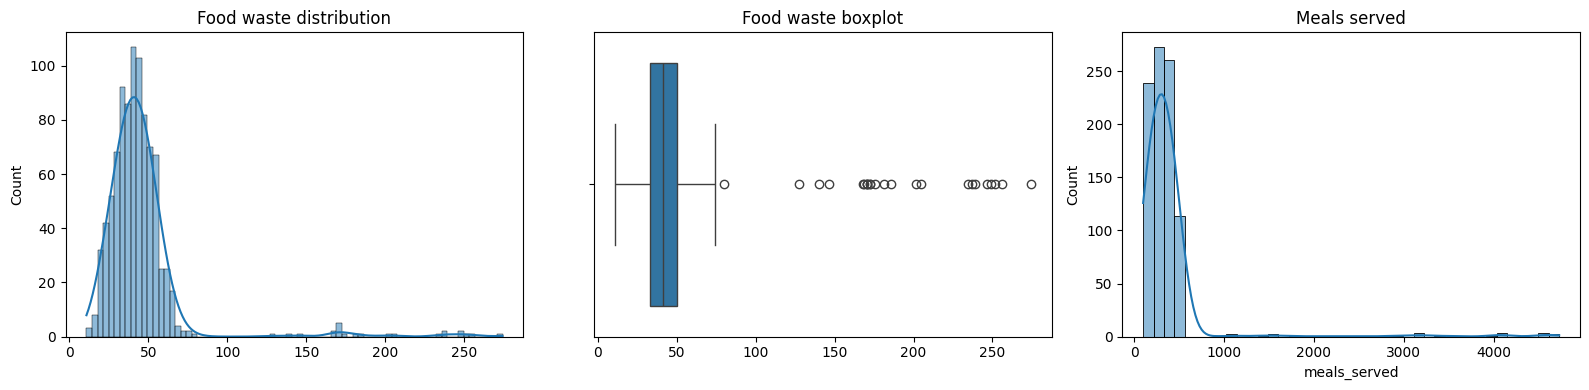

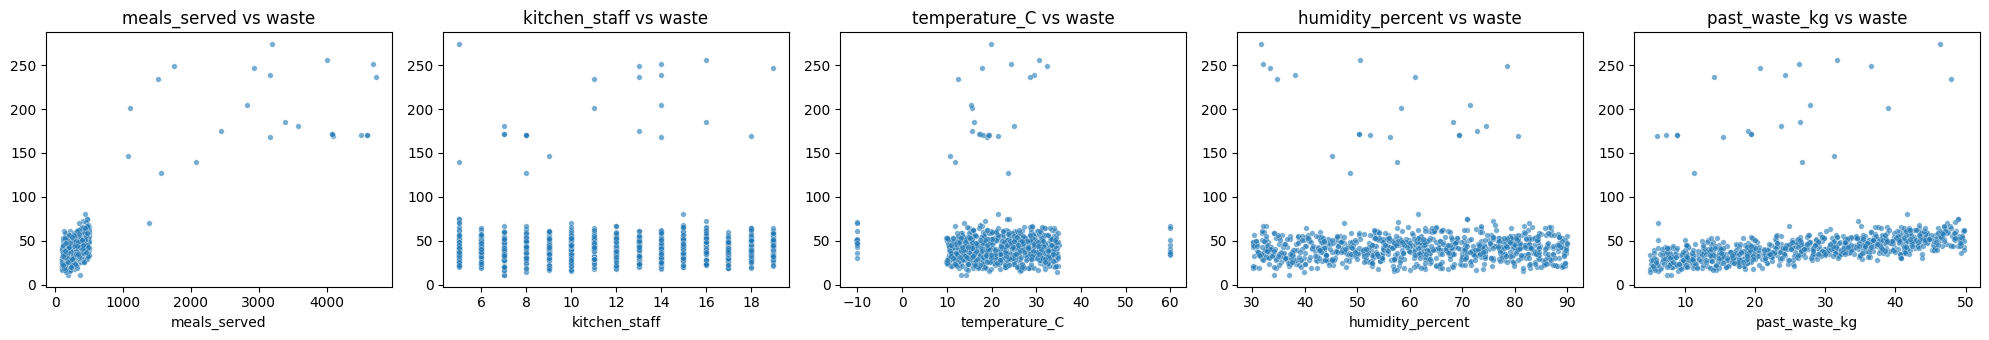

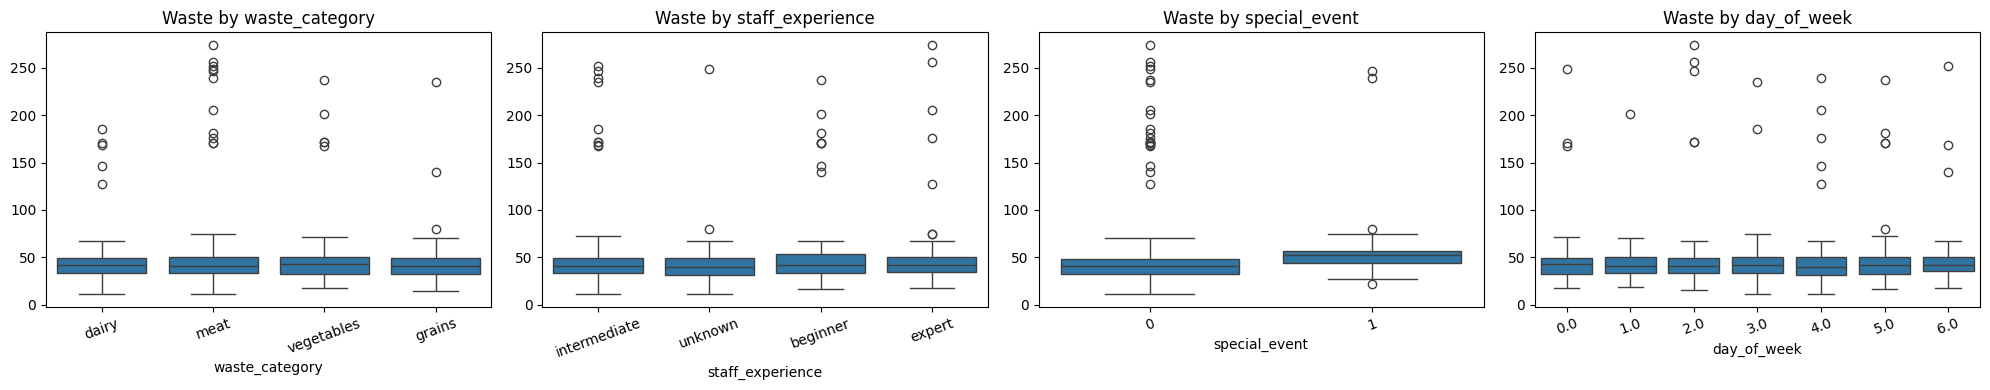

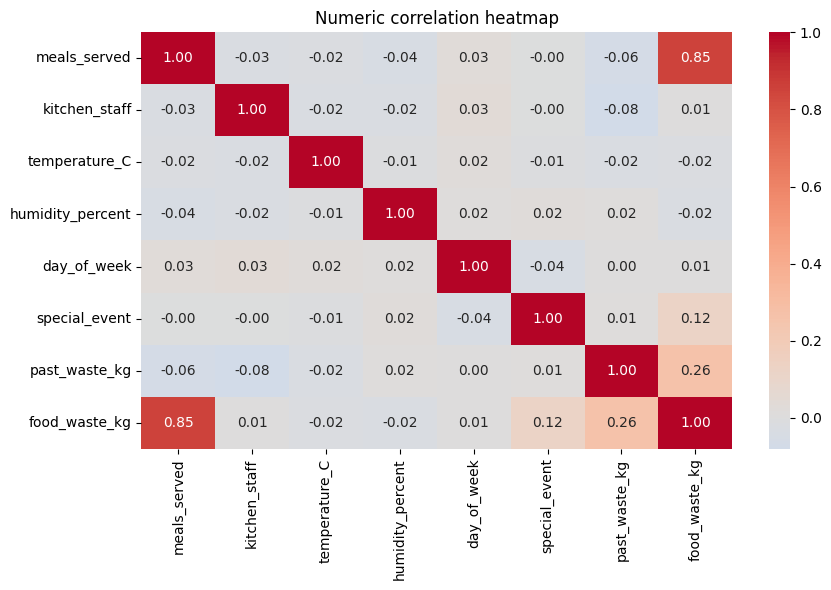

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(y, kde=True, ax=ax[0])
ax[0].set_title("Food waste distribution")
sns.boxplot(x=y, ax=ax[1])
ax[1].set_title("Food waste boxplot")
sns.histplot(X["meals_served"], bins=40, kde=True, ax=ax[2])
ax[2].set_title("Meals served")
plt.tight_layout()
plt.show()

num_cols_eda = ["meals_served", "kitchen_staff", "temperature_C", "humidity_percent", "past_waste_kg"]
fig, ax = plt.subplots(1, len(num_cols_eda), figsize=(20, 3.5))
for a, c in zip(ax, num_cols_eda):
    sns.scatterplot(x=X[c], y=y, s=16, alpha=0.6, ax=a)
    a.set_title(f"{c} vs waste")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, c in zip(ax, ["waste_category", "staff_experience", "special_event", "day_of_week"]):
    sns.boxplot(x=X[c].fillna("unknown"), y=y, ax=a)
    a.set_title(f"Waste by {c}")
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

eda_frame = X.copy()
eda_frame[TARGET] = y
corr = eda_frame.select_dtypes(include=np.number).corr()
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numeric correlation heatmap")
plt.tight_layout()
plt.show()

## 6. Feature engineering and preprocessing

In [9]:
FE = prepare(X)
print("Engineered feature shape:", FE.shape)
display(FE.head(3))

# Version-compatible OneHotEncoder for different sklearn releases.
def make_one_hot():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

def make_preprocessor(scale_numeric=True):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM_COLS),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", make_one_hot())
        ]), CAT_COLS)
    ], remainder="drop")

def make_model_pipeline(model, scale_numeric=True):
    return Pipeline([
        ("features", FunctionTransformer(prepare, validate=False)),
        ("preprocess", make_preprocessor(scale_numeric)),
        ("model", clone(model))
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Preprocessing and 5-fold cross-validation are ready.")

Engineered feature shape: (911, 24)


,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,year,month,day,...,experience_ord,log_meals,meals_per_staff,past_waste_per_meal,past_waste_per_staff,temp_x_humidity,hot_day,meals_x_event,waste_category,staff_experience
0,196.0,13.0,27.887273,45.362854,0.0,0,7.740587,2022,12,19,...,1.0,5.283204,15.076923,0.039493,0.595430,12.650463,0.0,0.0,dairy,intermediate
1,244.0,15.0,10.317872,64.430475,1.0,0,42.311779,2023,11,21,...,NaN,5.501258,16.266667,0.173409,2.820785,6.647854,0.0,0.0,meat,NaN
2,148.0,16.0,27.714300,69.046113,1.0,0,41.184305,2022,2,1,...,0.0,5.003946,9.250000,0.278272,2.574019,19.135647,0.0,0.0,meat,beginner


Preprocessing and 5-fold cross-validation are ready.


## 7. Regression — Linear, Random Forest and Gradient Boosting

In [10]:
reg_models = {
    "Linear Regression": make_model_pipeline(LinearRegression(), scale_numeric=True),
    "Random Forest Regressor": make_model_pipeline(
        RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
        scale_numeric=False
    ),
    # Added after comparing extra regressors (see 7b / model_comparison_regression.csv)
    "Gradient Boosting Regressor": make_model_pipeline(
        GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                  subsample=0.8, random_state=RANDOM_STATE),
        scale_numeric=False
    )
}

reg_rows = []
for name, model in reg_models.items():
    scores = cross_validate(
        model, X, y, cv=cv,
        scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"},
        n_jobs=-1
    )
    reg_rows.append({
        "Model": name,
        "MAE": -scores["test_mae"].mean(),
        "RMSE": -scores["test_rmse"].mean(),
        "R2": scores["test_r2"].mean()
    })

reg_results = pd.DataFrame(reg_rows).sort_values("RMSE").reset_index(drop=True)
display(reg_results.round(3))
best_reg_name = reg_results.loc[0, "Model"]
print("Best regression model:", best_reg_name)

,Model,MAE,RMSE,R2
0,Gradient Boosting Regressor,4.878,8.340,0.903
1,Random Forest Regressor,5.241,9.149,0.886
2,Linear Regression,5.618,11.069,0.824


Best regression model: Gradient Boosting Regressor


### 7b. Extra regression model: XGBoost (compared, not selected)
Same features, same preprocessing pipeline and the same 5-fold `cv` as section 7, so the numbers are directly comparable.
Preprocessing sits *inside* each pipeline, so imputation/scaling are fit on training folds only (no leakage).
Hyperparameters are fixed (not tuned on the evaluation folds). Gradient Boosting is now scored in section 7 itself.
Results are saved to `model_comparison_regression.csv`.

In [11]:
import time
try:
    from xgboost import XGBRegressor
    XGB_AVAILABLE = True
except Exception as e:
    XGB_AVAILABLE = False
    print("XGBoost not available:", repr(e), "-> skipping XGBoost Regressor")

new_reg_models = {}
if XGB_AVAILABLE:
    new_reg_models["XGBoost Regressor"] = make_model_pipeline(
        XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                     colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=1, tree_method="hist"),
        scale_numeric=False)

reg_scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
new_reg_rows = []
for name, model in new_reg_models.items():
    try:
        t0 = time.perf_counter()
        s = cross_validate(model, X, y, cv=cv, scoring=reg_scoring, n_jobs=1)
        new_reg_rows.append({
            "Task": "Regression", "Model": name, "Source": "new",
            "MAE": -s["test_mae"].mean(), "RMSE": -s["test_rmse"].mean(), "R2": s["test_r2"].mean(),
            "RMSE_fold_std": s["test_rmse"].std(), "Status": "completed",
            "Fit_Time_s": time.perf_counter() - t0})
    except Exception as e:
        print("FAILED:", name, repr(e))
        new_reg_rows.append({"Task": "Regression", "Model": name, "Source": "new", "Status": "failed: " + repr(e)})

# Models from section 7 (same folds, same pipeline) for a like-for-like table
old_reg = reg_results.assign(Task="Regression", Status="completed",
    Source=reg_results["Model"].map(lambda m: "new" if m == "Gradient Boosting Regressor" else "existing"))
reg_comparison = pd.concat([old_reg, pd.DataFrame(new_reg_rows)], ignore_index=True)
cols = ["Task", "Model", "Source", "MAE", "RMSE", "R2", "RMSE_fold_std", "Fit_Time_s", "Status"]
reg_comparison = reg_comparison.reindex(columns=cols).sort_values("RMSE").reset_index(drop=True)
reg_comparison.to_csv("model_comparison_regression.csv", index=False)
display(reg_comparison.round(3))
print("Saved: model_comparison_regression.csv")


,Task,Model,Source,MAE,RMSE,R2,RMSE_fold_std,Fit_Time_s,Status
0,Regression,Gradient Boosting Regressor,new,4.878,8.340,0.903,NaN,NaN,completed
1,Regression,XGBoost Regressor,new,5.018,9.120,0.885,2.46,2.216,completed
2,Regression,Random Forest Regressor,existing,5.241,9.149,0.886,NaN,NaN,completed
3,Regression,Linear Regression,existing,5.618,11.069,0.824,NaN,NaN,completed


Saved: model_comparison_regression.csv


## 8. Classification — Logistic Regression and Random Forest (new models compared in 8b)

In [12]:
# Create balanced Low/Medium/High classes using training-target tertiles.
q_low, q_high = np.quantile(y, [1/3, 2/3])
labels = np.array(["Low Waste", "Medium Waste", "High Waste"])
y_cls = labels[np.digitize(y, [q_low, q_high])]

print(f"Thresholds: Low <= {q_low:.2f} kg, Medium <= {q_high:.2f} kg, High > {q_high:.2f} kg")
print(pd.Series(y_cls).value_counts().sort_index())

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cls_models = {
    "Logistic Regression": make_model_pipeline(
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE), scale_numeric=True
    ),
    "Random Forest Classifier": make_model_pipeline(
        RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
        scale_numeric=False
    )
}

cls_rows = []
for name, model in cls_models.items():
    scores = cross_validate(
        model, X, y_cls, cv=skf,
        scoring={"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"},
        n_jobs=-1
    )
    cls_rows.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean()
    })

cls_results = pd.DataFrame(cls_rows).sort_values("F1", ascending=False).reset_index(drop=True)
display(cls_results.round(3))
best_cls_name = cls_results.loc[0, "Model"]
print("Best classification model:", best_cls_name)

Thresholds: Low <= 35.64 kg, Medium <= 46.65 kg, High > 46.65 kg
High Waste      304
Low Waste       304
Medium Waste    303
Name: count, dtype: int64


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.744,0.748,0.744,0.745
1,Random Forest Classifier,0.737,0.742,0.737,0.737


Best classification model: Logistic Regression


### 8b. Extra classifiers: XGBoost and Extra Trees (Batch 2)
Two evaluations, same 5 stratified folds (`skf`), same features and pipeline as the existing classifiers:
1. **Original labels** - uses `y_cls` from above, so numbers are directly comparable to the existing 74% result.
2. **Leak-free labels** - the Low/Medium/High cut-offs are recomputed from the *training fold only* and applied to the held-out fold (the original cut-offs use all rows, a small leak).
Hyperparameters are fixed, not tuned on the evaluation folds. Results go to `model_comparison_classification.csv`.

**Selection decision:** the existing selection in section 8 is kept (Logistic Regression). Extra Trees is ~1 point more accurate on the original labels, but that is within fold-to-fold noise, and on the leak-free labels it is essentially tied with Logistic Regression.

In [13]:
import time
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
try:
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
except Exception as e:
    XGB_AVAILABLE = False
    print("XGBoost not available:", repr(e), "-> skipping XGBoost Classifier")

# XGBoost needs integer class labels; labels order is Low, Medium, High -> 0, 1, 2
label_to_int = {l: i for i, l in enumerate(labels)}
y_cls_int = np.array([label_to_int[v] for v in y_cls])

new_cls_models = {
    "Extra Trees Classifier": make_model_pipeline(
        ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1),
        scale_numeric=False)
}
if XGB_AVAILABLE:
    new_cls_models["XGBoost Classifier"] = make_model_pipeline(
        XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                      colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=1, tree_method="hist"),
        scale_numeric=False)

cls_scoring = {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}
rows = []

# (1) Original labels, same protocol as section 8 -------------------------------------------
for name, model in new_cls_models.items():
    try:
        t0 = time.perf_counter()
        yy = y_cls_int if name == "XGBoost Classifier" else y_cls
        s = cross_validate(model, X, yy, cv=skf, scoring=cls_scoring, n_jobs=1)
        rows.append({"Task": "Classification", "Model": name, "Source": "new", "Protocol": "original_labels",
                     "Accuracy": s["test_accuracy"].mean(), "Precision": s["test_precision"].mean(),
                     "Recall": s["test_recall"].mean(), "F1": s["test_f1"].mean(),
                     "Accuracy_fold_std": s["test_accuracy"].std(), "Fit_Time_s": time.perf_counter() - t0,
                     "Status": "completed"})
    except Exception as e:
        print("FAILED:", name, repr(e))
        rows.append({"Task": "Classification", "Model": name, "Source": "new", "Protocol": "original_labels",
                     "Status": "failed: " + repr(e)})
for _, r in cls_results.iterrows():          # existing models, already scored in section 8
    rows.append({"Task": "Classification", "Model": r["Model"], "Source": "existing", "Protocol": "original_labels",
                 "Accuracy": r["Accuracy"], "Precision": r["Precision"], "Recall": r["Recall"], "F1": r["F1"],
                 "Status": "completed"})

# (2) Leak-free labels: thresholds from the training fold only --------------------------------
all_cls_models = {**{n: (m, "existing") for n, m in cls_models.items()},
                  **{n: (m, "new") for n, m in new_cls_models.items()}}
for name, (model, src) in all_cls_models.items():
    try:
        t0 = time.perf_counter()
        acc, pre, rec, f1s = [], [], [], []
        for tr, te in skf.split(X, y_cls):
            lo, hi = np.quantile(y[tr], [1/3, 2/3])
            ytr, yte = np.digitize(y[tr], [lo, hi]), np.digitize(y[te], [lo, hi])
            m = clone(model).fit(X.iloc[tr], ytr)
            p = m.predict(X.iloc[te])
            acc.append(accuracy_score(yte, p))
            pre.append(precision_score(yte, p, average="macro", zero_division=0))
            rec.append(recall_score(yte, p, average="macro", zero_division=0))
            f1s.append(f1_score(yte, p, average="macro", zero_division=0))
        rows.append({"Task": "Classification", "Model": name, "Source": src, "Protocol": "leak_free_labels",
                     "Accuracy": np.mean(acc), "Precision": np.mean(pre), "Recall": np.mean(rec), "F1": np.mean(f1s),
                     "Accuracy_fold_std": np.std(acc), "Fit_Time_s": time.perf_counter() - t0, "Status": "completed"})
    except Exception as e:
        print("FAILED (leak-free):", name, repr(e))
        rows.append({"Task": "Classification", "Model": name, "Source": src, "Protocol": "leak_free_labels",
                     "Status": "failed: " + repr(e)})

cols = ["Task", "Model", "Source", "Protocol", "Accuracy", "Precision", "Recall", "F1",
        "Accuracy_fold_std", "Fit_Time_s", "Status"]
cls_comparison = pd.DataFrame(rows).reindex(columns=cols).sort_values(["Protocol", "F1"], ascending=[True, False]).reset_index(drop=True)
cls_comparison.to_csv("model_comparison_classification.csv", index=False)
display(cls_comparison.round(3))
print("Saved: model_comparison_classification.csv")


,Task,Model,Source,Protocol,Accuracy,Precision,Recall,F1,Accuracy_fold_std,Fit_Time_s,Status
0,Classification,Logistic Regression,existing,leak_free_labels,0.742,0.746,0.742,0.743,0.021,0.675,completed
1,Classification,Extra Trees Classifier,new,leak_free_labels,0.744,0.740,0.744,0.740,0.017,3.914,completed
2,Classification,Random Forest Classifier,existing,leak_free_labels,0.733,0.739,0.733,0.734,0.026,6.772,completed
3,Classification,XGBoost Classifier,new,leak_free_labels,0.734,0.736,0.734,0.733,0.027,4.312,completed
4,Classification,Logistic Regression,existing,original_labels,0.744,0.748,0.744,0.745,NaN,NaN,completed
5,Classification,Extra Trees Classifier,new,original_labels,0.750,0.747,0.750,0.744,0.017,3.599,completed
6,Classification,Random Forest Classifier,existing,original_labels,0.737,0.742,0.737,0.737,NaN,NaN,completed
7,Classification,XGBoost Classifier,new,original_labels,0.737,0.738,0.736,0.735,0.030,4.156,completed


Saved: model_comparison_classification.csv


## 9. Clustering — K-Means and Agglomerative

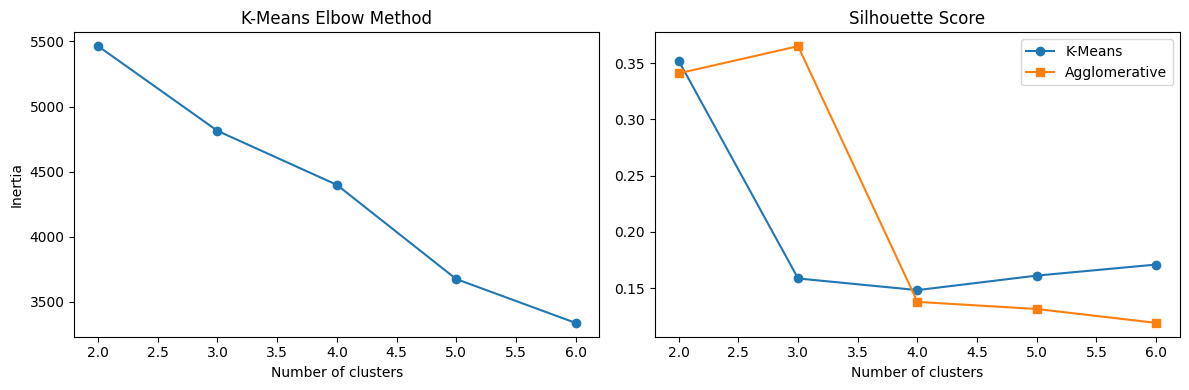

Selected k: 2
K-Means silhouette: 0.352
Agglomerative silhouette: 0.341


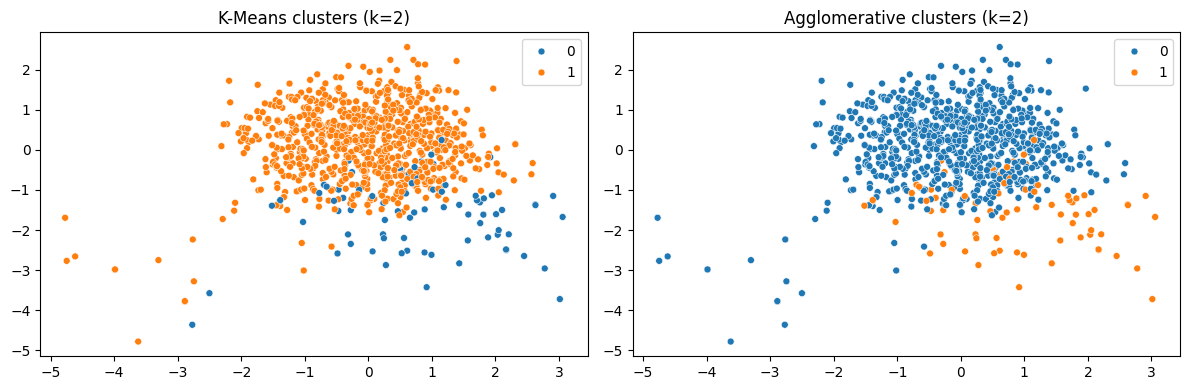

,meals_served,kitchen_staff,temperature_C,humidity_percent,past_waste_kg,day_of_week,special_event,food_waste_kg,count
cluster,,,,,,,,,
0,374.77,11.88,21.99,61.83,27.42,2.74,1.0,55.68,78
1,375.46,11.90,22.21,60.66,26.98,3.04,0.0,43.83,833


In [14]:
# Clustering uses input features only. food_waste_kg is NOT used to form clusters.
cluster_cols = ["meals_served", "kitchen_staff", "temperature_C", "humidity_percent", "past_waste_kg", "day_of_week", "special_event"]
Z_raw = FE[cluster_cols].copy()
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(Z_raw))

ks = range(2, 7)
inertias = []
kmeans_sil = []
agglom_sil = []
for k in ks:
    km_labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    ag_labels = AgglomerativeClustering(n_clusters=k).fit_predict(Z)
    inertias.append(KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z).inertia_)
    kmeans_sil.append(silhouette_score(Z, km_labels))
    agglom_sil.append(silhouette_score(Z, ag_labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertias, marker="o")
ax[0].set_title("K-Means Elbow Method")
ax[0].set_xlabel("Number of clusters")
ax[0].set_ylabel("Inertia")
ax[1].plot(list(ks), kmeans_sil, marker="o", label="K-Means")
ax[1].plot(list(ks), agglom_sil, marker="s", label="Agglomerative")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Number of clusters")
ax[1].legend()
plt.tight_layout()
plt.show()

best_k = list(ks)[int(np.argmax(kmeans_sil))]
km = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
ag = AgglomerativeClustering(n_clusters=best_k)
km_labels = km.fit_predict(Z)
ag_labels = ag.fit_predict(Z)

print("Selected k:", best_k)
print("K-Means silhouette:", round(float(silhouette_score(Z, km_labels)), 3))
print("Agglomerative silhouette:", round(float(silhouette_score(Z, ag_labels)), 3))

pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x=P[:,0], y=P[:,1], hue=km_labels, palette="tab10", s=25, ax=ax[0])
ax[0].set_title(f"K-Means clusters (k={best_k})")
sns.scatterplot(x=P[:,0], y=P[:,1], hue=ag_labels, palette="tab10", s=25, ax=ax[1])
ax[1].set_title(f"Agglomerative clusters (k={best_k})")
plt.tight_layout()
plt.show()

cluster_profile = FE[cluster_cols].copy()
cluster_profile[TARGET] = y
cluster_profile["cluster"] = km_labels
profile = cluster_profile.groupby("cluster").mean(numeric_only=True).round(2)
profile["count"] = pd.Series(km_labels).value_counts().sort_index()
display(profile)

### 9b. Clustering comparison table (Batch 3)
Clustering is unsupervised, so there is no train/test split and `food_waste_kg` is never used to form clusters (no leakage).
Silhouette is an *internal* score, so it is only comparable between runs on the **same feature set**. I score K-Means and Agglomerative (Ward) for k = 2-8 on:
- **A. existing features** (the 7 columns used in section 9, including the binary `special_event` and `day_of_week`)
- **B. continuous features only** (drops `special_event` and `day_of_week`), to check whether the binary column is driving the clusters.
Results go to `model_comparison_clustering.csv`.

In [15]:
from sklearn.metrics import adjusted_rand_score

feature_sets = {
    "A_existing_7_features": cluster_cols,
    "B_continuous_only": [c for c in cluster_cols if c not in ("special_event", "day_of_week")],
}
clu_rows = []
labels_store = {}
for fs_name, cols_ in feature_sets.items():
    Zf = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(FE[cols_]))
    for k in range(2, 9):
        for algo, make in [("K-Means", lambda k: KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)),
                           ("Agglomerative Clustering", lambda k: AgglomerativeClustering(n_clusters=k))]:
            try:
                lab = make(k).fit_predict(Zf)
                labels_store[(fs_name, algo, k)] = lab
                clu_rows.append({"Task": "Clustering", "Model": algo, "Feature_Set": fs_name, "k": k,
                                 "Silhouette": silhouette_score(Zf, lab),
                                 "Cluster_Sizes": "/".join(map(str, sorted(np.bincount(lab), reverse=True))),
                                 "Smallest_Cluster_Pct": 100 * np.bincount(lab).min() / len(lab),
                                 "Status": "completed"})
            except Exception as e:
                clu_rows.append({"Task": "Clustering", "Model": algo, "Feature_Set": fs_name, "k": k,
                                 "Status": "failed: " + repr(e)})

cluster_comparison = pd.DataFrame(clu_rows)
cluster_comparison.to_csv("model_comparison_clustering.csv", index=False)

best_rows = cluster_comparison.sort_values("Silhouette", ascending=False).groupby(["Feature_Set", "Model"]).head(1)
display(best_rows.sort_values(["Feature_Set", "Model"]).round(3))

# Agreement between the two algorithms at the same k, and how much one binary column explains the k=2 split
for fs_name in feature_sets:
    for k in (2, 3, 4):
        ari = adjusted_rand_score(labels_store[(fs_name, "K-Means", k)], labels_store[(fs_name, "Agglomerative Clustering", k)])
        print(f"{fs_name} k={k}: K-Means vs Agglomerative agreement (ARI) = {ari:.2f}")
km2 = labels_store[("A_existing_7_features", "K-Means", 2)]
print("\nA, k=2 K-Means: share of rows where cluster == special_event:",
      round(float(max((km2 == FE["special_event"].values).mean(), (km2 != FE["special_event"].values).mean())), 3))
print("Saved: model_comparison_clustering.csv")


,Task,Model,Feature_Set,k,Silhouette,Cluster_Sizes,Smallest_Cluster_Pct,Status
3,Clustering,Agglomerative Clustering,A_existing_7_features,3,0.365,819/75/17,1.866,completed
0,Clustering,K-Means,A_existing_7_features,2,0.352,833/78,8.562,completed
15,Clustering,Agglomerative Clustering,B_continuous_only,2,0.632,894/17,1.866,completed
14,Clustering,K-Means,B_continuous_only,2,0.624,893/18,1.976,completed


A_existing_7_features k=2: K-Means vs Agglomerative agreement (ARI) = 0.97
A_existing_7_features k=3: K-Means vs Agglomerative agreement (ARI) = 0.23
A_existing_7_features k=4: K-Means vs Agglomerative agreement (ARI) = 0.12
B_continuous_only k=2: K-Means vs Agglomerative agreement (ARI) = 0.97
B_continuous_only k=3: K-Means vs Agglomerative agreement (ARI) = 0.22
B_continuous_only k=4: K-Means vs Agglomerative agreement (ARI) = 0.39

A, k=2 K-Means: share of rows where cluster == special_event: 1.0
Saved: model_comparison_clustering.csv


## 10. Feature importance of the best regression model

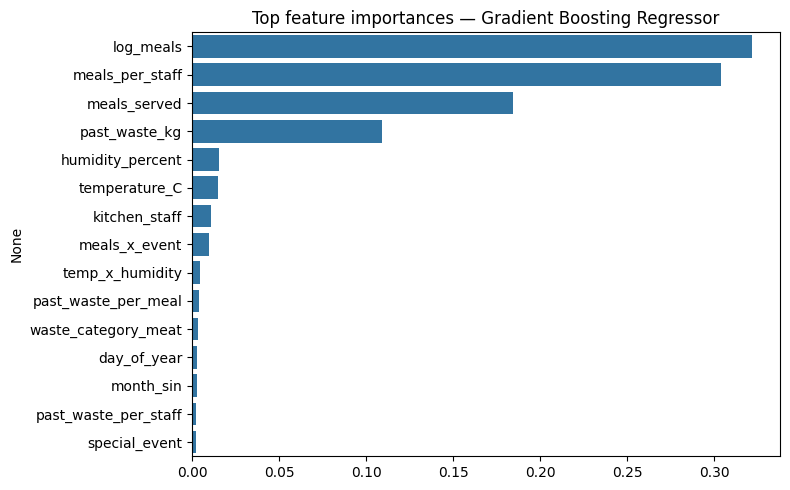

In [16]:
best_reg_model = clone(reg_models[best_reg_name])
best_reg_model.fit(X, y)

if hasattr(best_reg_model.named_steps["model"], "feature_importances_"):
    feature_names = best_reg_model.named_steps["preprocess"].get_feature_names_out()
    importances = best_reg_model.named_steps["model"].feature_importances_
    imp = pd.Series(importances, index=[n.split("__", 1)[-1] for n in feature_names]).sort_values(ascending=False).head(15)
    plt.figure(figsize=(8, 5))
    sns.barplot(x=imp.values, y=imp.index)
    plt.title(f"Top feature importances — {best_reg_name}")
    plt.tight_layout()
    plt.show()
else:
    print(f"{best_reg_name} selected; using permutation importance on raw input columns.")
    X_a, X_b, y_a, y_b = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
    best_reg_model.fit(X_a, y_a)
    pi = permutation_importance(best_reg_model, X_b, y_b, n_repeats=10, random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error", n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
    display(imp.to_frame("RMSE importance").round(4))


## 11. Train best models and predict test data

In [17]:
# Refit the best regression model on all cleaned training rows.
final_reg_model = clone(reg_models[best_reg_name]).fit(X, y)

# Refit the best classifier on all training rows.
final_cls_model = clone(cls_models[best_cls_name]).fit(X, y_cls)

X_test = test_raw[FEATURE_COLS].copy()
reg_pred = np.clip(final_reg_model.predict(X_test), 0, None)
cls_pred = final_cls_model.predict(X_test)

print("Regression predictions:", len(reg_pred))
print("Classification predictions:", len(cls_pred))
print("First 5 predicted waste values:", np.round(reg_pred[:5], 2))
print("First 5 waste levels:", cls_pred[:5])

Regression predictions: 911
Classification predictions: 911
First 5 predicted waste values: [24.82 47.23 48.78 45.49 43.7 ]
First 5 waste levels: ['Low Waste' 'High Waste' 'Medium Waste' 'Medium Waste' 'Medium Waste']


## 12. Create the Kaggle submission file

In [18]:
# Preserve the submission template's column order.
submission = sub_raw.copy()

if "ID" in submission.columns:
    submission["ID"] = test_raw["ID"].values

if TARGET in submission.columns:
    submission[TARGET] = reg_pred
else:
    # Common case: submission template has ID + target; if target is absent, create it.
    submission[TARGET] = reg_pred

submission = submission[[c for c in sub_raw.columns if c in submission.columns] + ([TARGET] if TARGET not in sub_raw.columns else [])]
submission.to_csv("final_submission.csv", index=False)

print("Saved: final_submission.csv")
print("Shape:", submission.shape)
display(submission.head())

Saved: final_submission.csv
Shape: (911, 2)


,ID,food_waste_kg
0,0,24.817503
1,1,47.227600
2,4,48.781983
3,5,45.487442
4,6,43.703369


## 13. Save the trained models and classification thresholds

In [19]:
joblib.dump(final_reg_model, "food_waste_best_regression_model.pkl")
joblib.dump(final_cls_model, "food_waste_best_classification_model.pkl")

with open("food_waste_thresholds.json", "w") as f:
    json.dump({"low_threshold": float(q_low), "high_threshold": float(q_high), "labels": labels.tolist()}, f, indent=2)

with open("food_waste_model_meta.json", "w") as f:
    json.dump({
        "target": TARGET,
        "regression_model": best_reg_name,
        "classification_model": best_cls_name,
        "input_columns": FEATURE_COLS
    }, f, indent=2)

print("Saved model files and metadata.")

Saved model files and metadata.


## 14. Food-waste recommendation function

In [20]:
def predict_food_waste(input_data):
    """Predict food waste and give a simple operational recommendation."""
    df = pd.DataFrame([input_data]) if isinstance(input_data, dict) else pd.DataFrame(input_data).copy()
    for c in FEATURE_COLS:
        if c not in df.columns:
            df[c] = np.nan
    df = df[FEATURE_COLS]

    pred_kg = np.clip(final_reg_model.predict(df), 0, None)
    level = final_cls_model.predict(df)
    results = []

    for kg, lv, (_, row) in zip(pred_kg, level, df.iterrows()):
        if lv == "Low Waste":
            tip = "Maintain current preparation and portioning levels."
        elif lv == "Medium Waste":
            tip = "Reduce batch sizes slightly and monitor leftovers by shift."
        else:
            tip = "Prepare smaller batches, improve demand planning, and plan surplus reuse or redistribution."

        extras = []
        if pd.notna(row.get("special_event")) and row.get("special_event") == 1:
            extras.append("confirm event headcount before preparation")
        if pd.notna(row.get("temperature_C")) and row.get("temperature_C") >= 30:
            extras.append("tighten cold-storage and perishable-food turnover")
        if str(row.get("staff_experience")).lower() == "beginner":
            extras.append("support newer staff with portion-control guidance")

        if extras:
            tip += " Also: " + "; ".join(extras) + "."
        results.append({"predicted_food_waste_kg": round(float(kg), 2), "waste_level": lv, "recommendation": tip})

    return results[0] if isinstance(input_data, dict) else results

print("Recommendation function created.")

Recommendation function created.


## 15. Example prediction

In [21]:
example_input = {
    "date": str(train["date"].dropna().iloc[-1].date()) if train["date"].notna().any() else "2026-01-01",
    "meals_served": 300,
    "kitchen_staff": 12,
    "temperature_C": 25,
    "humidity_percent": 60,
    "day_of_week": 2,
    "special_event": 0,
    "past_waste_kg": 25,
    "staff_experience": "intermediate",
    "waste_category": "vegetables"
}
print(predict_food_waste(example_input))

{'predicted_food_waste_kg': 38.76, 'waste_level': np.str_('Medium Waste'), 'recommendation': 'Reduce batch sizes slightly and monitor leftovers by shift.'}


## 16. Final project results

In [22]:
print("=" * 60)
print("RESTAURANT FOOD WASTAGE PREDICTION AND MANAGEMENT SYSTEM")
print("=" * 60)
print("Best Regression Model:", best_reg_name)
print("Regression RMSE:", round(float(reg_results.loc[0, "RMSE"]), 3))
print("Regression MAE :", round(float(reg_results.loc[0, "MAE"]), 3))
print("Regression R2  :", round(float(reg_results.loc[0, "R2"]), 3))
print()
print("Best Classification Model:", best_cls_name)
print("Classification Accuracy:", round(float(cls_results.loc[0, "Accuracy"]), 3))
print("Classification F1      :", round(float(cls_results.loc[0, "F1"]), 3))
print()
print("Clustering algorithms: K-Means and Agglomerative Clustering")
print("Selected number of clusters:", best_k)
print()
print("Files created:")
print("- final_submission.csv")
print("- food_waste_best_regression_model.pkl")
print("- food_waste_best_classification_model.pkl")
print("- food_waste_thresholds.json")
print("- food_waste_model_meta.json")
print("- model_comparison_regression.csv / model_comparison_classification.csv / model_comparison_clustering.csv / model_comparison_summary.csv (extra comparison files)")
print("=" * 60)

RESTAURANT FOOD WASTAGE PREDICTION AND MANAGEMENT SYSTEM
Best Regression Model: Gradient Boosting Regressor
Regression RMSE: 8.34
Regression MAE : 4.878
Regression R2  : 0.903

Best Classification Model: Logistic Regression
Classification Accuracy: 0.744
Classification F1      : 0.745

Clustering algorithms: K-Means and Agglomerative Clustering
Selected number of clusters: 2

Files created:
- final_submission.csv
- food_waste_best_regression_model.pkl
- food_waste_best_classification_model.pkl
- food_waste_thresholds.json
- food_waste_model_meta.json
- model_comparison_regression.csv / model_comparison_classification.csv / model_comparison_clustering.csv / model_comparison_summary.csv (extra comparison files)


## 17. Combined model comparison summary
One table with every model that was compared (existing + new), the metrics actually measured, and which model each task uses in the pipeline. Saved as `model_comparison_summary.csv` (extra file; the original output files are unchanged in structure).

In [23]:
summary_cols = ["Task", "Model", "Source", "Protocol", "Feature_Set", "k", "MAE", "RMSE", "R2",
                "Accuracy", "Precision", "Recall", "F1", "Silhouette", "Selected_for_pipeline"]
parts = []

r = reg_comparison.copy()
r["Protocol"] = "5-fold CV"
r["Selected_for_pipeline"] = r["Model"].eq(best_reg_name)
parts.append(r)

c = cls_comparison.copy()
c["Selected_for_pipeline"] = c["Model"].eq(best_cls_name) & c["Protocol"].eq("original_labels")
parts.append(c)

k_ = cluster_comparison.copy()
k_["Protocol"] = "unsupervised (internal score)"
k_["Selected_for_pipeline"] = (k_["Feature_Set"].eq("A_existing_7_features") & k_["k"].eq(best_k)
                               & k_["Model"].isin(["K-Means", "Agglomerative Clustering"]))
parts.append(k_)

summary = pd.concat(parts, ignore_index=True).reindex(columns=summary_cols)
summary.to_csv("model_comparison_summary.csv", index=False)
display(summary[summary["Selected_for_pipeline"] == True].round(3))
print("Saved: model_comparison_summary.csv", summary.shape)


,Task,Model,Source,Protocol,Feature_Set,k,MAE,RMSE,R2,Accuracy,Precision,Recall,F1,Silhouette,Selected_for_pipeline
0,Regression,Gradient Boosting Regressor,new,5-fold CV,NaN,NaN,4.878,8.34,0.903,NaN,NaN,NaN,NaN,NaN,True
8,Classification,Logistic Regression,existing,original_labels,NaN,NaN,NaN,NaN,NaN,0.744,0.748,0.744,0.745,NaN,True
12,Clustering,K-Means,NaN,unsupervised (internal score),A_existing_7_features,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.352,True
13,Clustering,Agglomerative Clustering,NaN,unsupervised (internal score),A_existing_7_features,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.341,True


Saved: model_comparison_summary.csv (40, 15)
